# Batch correction with bixverse

*Python port of the R vignette [Batch correction with bixverse](https://gregorlueg.github.io/bixverse/articles/single_cell_batch_corrections.html). Original authors: Grant Neilson, Gregor Lueg and Liesbeth François.*

## Intro

Batch effects are systematic technical differences between experimental runs
that can obscure genuine biological signal in single cell data. When datasets
from multiple experiments, technologies, or laboratories are combined, cells
tend to group by their source rather than by cell type. Batch correction
methods aim to remove these technical artefacts whilst preserving biological
variation.

`bixverse` provides four batch correction approaches, each with different
trade-offs:

- **fastMNN** ([Haghverdi, et al., 2018](https://doi.org/10.1038/nbt.4091))
  identifies mutual nearest neighbours across batches: pairs of cells from
  different batches that are each other's closest match. Correction vectors
  are computed from these pairs and applied to align the embeddings. It is
  particularly effective when cell type composition differs across batches.
- **Harmony** ([Korsunsky, et al., 2019](https://doi.org/10.1038/s41592-019-0619-0))
  operates on PCA embeddings using iterative soft clustering with diversity
  penalties. It assigns cells to clusters, estimates batch effects per cluster
  via ridge regression, and corrects the embedding. It tends to be fast and
  works well across a range of scenarios. A version 2 has been released too,
  see [Patikas, et al., 2026](https://www.biorxiv.org/content/10.64898/2026.03.16.711825v1),
  with improvements that increase scalability to larger data sets and
  modifications to the objective functions to not overcorrect across batches
  when different cell types are there.
- **BBKNN** ([Polanski, et al., 2020](https://doi.org/10.1093/bioinformatics/btz625))
  takes a fundamentally different approach. Rather than correcting an
  embedding, it constructs a batch-balanced k-nearest neighbour graph by
  building separate neighbour indices per batch. The corrected graph can then
  be used directly for clustering and visualisation.
- **Seurat anchors** ([Stuart, et al., 2019](https://doi.org/10.1016/j.cell.2019.05.031))
  find pairs of cells that are mutual nearest neighbours in a space shared by
  two batches, score them by how much of their neighbourhood they share, and
  use them to pull one batch onto the other. Two flavours are available. CCA
  builds the shared space from canonical correlations and corrects hardest,
  which suits batches that don't share their cell types. rPCA projects each
  batch into the other's PCA basis instead: cheaper, gentler, and the better
  default when the batches broadly match. Both need batch-aware HVGs.

A correction has two jobs: mix the batches and keep the biology intact. Going
too hard on the first ruins the second, so `bixverse` scores both, following
the scIB benchmark ([Luecken, et al., 2022](https://doi.org/10.1038/s41592-021-01336-8)).

Batch mixing:

- **kBET**: tests whether neighbourhood batch proportions match the global
  ones.
- **Batch ASW**: silhouette width on batch labels in the embedding.
- **iLISI**: effective number of batches per neighbourhood. Works on any kNN
  graph.
- **PCR**: how much of the embedding variance batch explains, before versus
  after correction.

Bio conservation, which needs cell type labels:

- **cLISI**: effective number of cell types per neighbourhood. You want one.
- **Cell type ASW**: silhouette width on cell type labels.
- **Graph connectivity**: whether each cell type stays one connected piece of
  the kNN graph.

`bv.integrate.calculate_integration_metrics()` runs the lot and returns one
row, every column rescaled so that higher is better.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
import bixverse.embed

## Preparing the data

### Loading the batches

We use two PBMC datasets (pbmc3k and pbmc4k) as a standard benchmark for
batch correction. These come from the same tissue but differ in sequencing
depth and cell counts, introducing a clear batch effect.

In [2]:
dir_data = bv.io.download_pbmc_batches()

tempdir_batch_cor = tempfile.TemporaryDirectory()

h5ad_paths = {
    "pbmc3k": dir_data / "pbmc3k.h5ad",
    "pbmc4k": dir_data / "pbmc4k.h5ad",
}

h5_tasks = bv.io.prescan_h5ad_files(h5ad_paths)

sc = bv.io.load_multi_h5ad(
    Path(tempdir_batch_cor.name) / "batch_cor",
    h5_tasks,
    verbose=True,
)

sc

Scan 1/2: Counting gene expression across 2 files...
  Scanning genes in pbmc3k...
  Scanning genes in pbmc4k...
  Genes passing global QC: 13_925 / 31_232
Scan 2/2: Computing cell QC with final gene set...
  Scanning cells in pbmc3k...
  Scanning cells in pbmc4k...
  pbmc3k: 2_700 / 2_700 cells passing QC
  pbmc4k: 4_340 / 4_340 cells passing QC
  Total cells: 7_040
Writing cells to binary...
  Writing pbmc3k (2_700 cells)...
  Writing pbmc4k (4_340 cells)...
Multi-h5ad loading complete: 155.72ms
  Counted 7_889_186 non-zeros over 13_925 genes in 3.11ms; converting in 1 phase(s).


  Phase 1/1: genes 0-13925, scatter 13.97ms, compress + write 58.29ms
  Conversion into gene-friendly format done: 76.56ms


SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpsqlh4gsq/batch_cor',
  cells=7040 (kept 7040), genes=13925,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

### Quality control

Before batch correction, we filter out low-quality cells using mitochondrial
gene proportions and library complexity metrics. In a multi file import the
additional var columns are dropped, so the gene symbols come from one of the
h5ad files.

In [3]:
h5_metadata = bv.io.read_h5ad_metadata(h5ad_paths["pbmc3k"])

var = sc.var().join(
    h5_metadata["var"].select(
        pl.col("ensembl_id").alias("gene_id"),
        pl.col("symbol_tenx").alias("gene_symbol"),
    ),
    on="gene_id",
)

gs_of_interest = {
    "MT": var.filter(pl.col("gene_symbol").str.contains("^MT-"))["gene_id"].to_list(),
    "Ribo": var.filter(pl.col("gene_symbol").str.contains("^RP[SL]"))[
        "gene_id"
    ].to_list(),
}

bv.qc.gene_set_proportions(sc, gs_of_interest, streaming=False, verbose=True)

qc_df = sc.obs(cols=["cell_id", "lib_size", "nnz", "MT"])

metrics = {
    "log10_lib_size": np.log10(qc_df["lib_size"].to_numpy()),
    "log10_nnz": np.log10(qc_df["nnz"].to_numpy()),
    "MT": qc_df["MT"].to_numpy(),
}

directions = {
    "log10_lib_size": "twosided",
    "log10_nnz": "twosided",
    "MT": "above",
}

qc = bv.qc.run_cell_qc(
    metrics,
    sc.cells_to_keep,
    directions=directions,
    threshold=3.0,
)

# set the cells to keep
sc.add_obs(pl.DataFrame({"cell_idx": qc.cell_idx, "outlier": qc.combined}))
sc.set_cells_to_keep(qc.cell_idx[~qc.combined])

sc

Load in data: 6.84ms
Finished the gene set proportion calculations: 2.15ms


SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpsqlh4gsq/batch_cor',
  cells=7040 (kept 6626), genes=13925,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

### Pre-processing

Standard pre-processing: HVG selection, PCA, and neighbour computation.

In [4]:
bv.pp.find_hvg(sc, hvg_no=2000, verbose=True)

bv.pp.calculate_pca(sc, no_pcs=30)

bv.graph.find_neighbours(sc)

HVG (VST): 13_925 genes, 1 batches, 1 disk block(s)
HVG (VST): Calculated gene statistics in 9.17ms
HVG (VST): Fitted Loess in 558.62µs
HVG (VST): Standardised variance in 745.58µs (690 gene(s) re-read for the clip)
HVG (VST): Total run time -> 10.52ms


### Cell type labels

The bio conservation metrics need cell types. We cluster the uncorrected data
and annotate the clusters with scType
([Ianevski, et al., 2022](https://doi.org/10.1038/s41467-022-28803-w)) on a
handful of canonical PBMC markers, same as in the
[PBMC vignette](pbmc_single_cell.ipynb). The labels are deliberately coarse:
T cells stay lumped, since splitting CD4 from CD8 on uncorrected data is
asking for trouble.

One caveat: the labels come from uncorrected data, so they carry whatever
the batch effect did to the clusters. Good enough to spot a method that
smears cell types together, not a ground truth.

In [5]:
bv.graph.find_clusters(sc, res=1.0, name="leiden_uncorrected")

cell_markers = {
    "CD3D": "T cells",
    "CD3E": "T cells",
    "IL7R": "T cells",
    "CD8A": "T cells",
    "MS4A1": "B cells",
    "CD79A": "B cells",
    "CD14": "Monocytes",
    "LYZ": "Monocytes",
    "FCGR3A": "Monocytes",
    "GNLY": "NK",
    "NKG7": "NK",
    "FCER1A": "DC",
    "CD1C": "DC",
    "PPBP": "Platelets",
}

cell_markers_df = pl.DataFrame(
    {"gene_symbol": list(cell_markers), "cell_type": list(cell_markers.values())}
).join(var.select("gene_symbol", "gene_id"), on="gene_symbol")

marker_list = bv.annotate.prepare_cell_markers(sc, cell_markers_df)

sctype_scores = bv.annotate.calc_sc_type_scores(sc, marker_list)

obs = sc.obs(cols=["cell_idx", "leiden_uncorrected"], filtered=True)

cell_type_anno = bv.annotate.score_clusters(
    sctype_scores, obs["leiden_uncorrected"].to_numpy()
)

obs = obs.join(
    cell_type_anno.select(
        pl.col("cluster_id").alias("leiden_uncorrected"), "cell_type"
    ),
    on="leiden_uncorrected",
    how="left",
)

sc.add_obs(obs.select("cell_idx", "cell_type"))

obs["cell_type"].value_counts(sort=True)

cell_type,count
str,u32
"""T cells""",3192
"""Monocytes""",1421
"""B cells""",933
"""NK""",889
"""DC""",163
"""Platelets""",28


## Comparing the different methods

Let's check out the different methods and how they behave.

### Uncorrected data

Before applying any correction, we can visualise the batch effect and compute
baseline metrics. All t-SNEs here use the quick-and-dirty Barnes-Hut
optimiser.

In [6]:
bv.embed.tsne(sc, params=bv.embed.tsne_defaults().set_params(approx="qd"))

tSNE plot (tSNEs usually look prettier... It's anyway not a good way to
assess batch effect correction, so at least let's make it pleasant on the
eye).

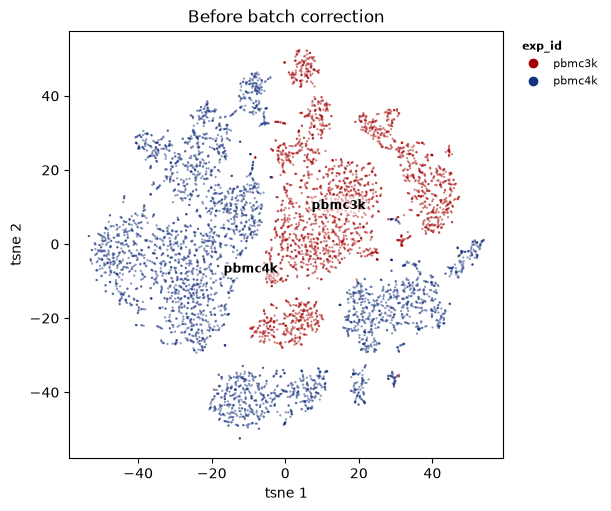

In [7]:
ax = bv.pl.embedding_plot(sc, "tsne", "exp_id", label_by="exp_id", discrete=True)
ax.set_title("Before batch correction")
plt.show()

Each metric has its own function and its own result record. Here's kBET on
its own:

In [8]:
kbet = bv.integrate.calculate_kbet(sc, "exp_id")

print(
    f"kBET rejection rate: {kbet.kbet_score:.3f} over {kbet.n_batches} batches "
    f"(median chi-square {kbet.median_chi_square:.2f})"
)

kBET rejection rate: 0.987 over 2 batches (median chi-square 8.17)


In practice, you'd want all of them at once.
`calculate_integration_metrics()` gives one row per call, and we'll stack one
row per method into `metrics_df`:

In [9]:
metrics_df = bv.integrate.calculate_integration_metrics(
    sc, "exp_id", cell_type_column="cell_type"
).with_columns(method=pl.lit("Uncorrected"))

metrics_df

embedding,kbet_accept,batch_asw,ilisi,pcr_comparison,clisi,cell_type_asw,graph_connectivity,method
str,f64,f64,f64,f64,f64,f64,f64,str
"""pca""",0.012979,0.906355,0.0,null,1.0,0.650836,0.950153,"""Uncorrected"""


The high kBET rejection rate (so a low `kbet_accept`) and a low `ilisi`
confirm a substantial batch effect, and the tSNE shows clear separation by
batch. `pcr_comparison` is null here: it compares a corrected embedding
against this PCA, so the PCA has nothing to compare against.

### fastMNN

fastMNN works on batch-aware HVGs and produces a corrected embedding. It
identifies mutual nearest neighbours across batches to compute correction
vectors. For it to work best, we need the batch-aware HVGs. We calculate
these, provide them to fastMNN (which regenerates the PCA embedding based on
the batch-aware HVGs) and then run the actual algorithm.

In [10]:
batch_aware_hvg = bv.pp.find_hvg_batch_aware(sc, "exp_id")

bv.integrate.fast_mnn(sc, "exp_id", batch_aware_hvg.hvg_gene_idx)

bv.graph.find_neighbours(sc, embd_to_use="mnn")

In [11]:
metrics_df = pl.concat(
    [
        metrics_df,
        bv.integrate.calculate_integration_metrics(
            sc, "exp_id", cell_type_column="cell_type", embd_to_use="mnn"
        ).with_columns(method=pl.lit("fastMNN")),
    ]
)

metrics_df.filter(pl.col("method") == "fastMNN")

embedding,kbet_accept,batch_asw,ilisi,pcr_comparison,clisi,cell_type_asw,graph_connectivity,method
str,f64,f64,f64,f64,f64,f64,f64,str
"""mnn""",0.684576,0.973649,0.470588,0.960004,1.0,0.649202,0.948964,"""fastMNN"""


We can see clear improvements on the batch side: kBET acceptance, batch ASW
and iLISI all go up.

In [12]:
bv.embed.tsne(
    sc,
    slot_name="tsne_mnn",
    use_knn=True,
    params=bv.embed.tsne_defaults().set_params(approx="qd"),
)

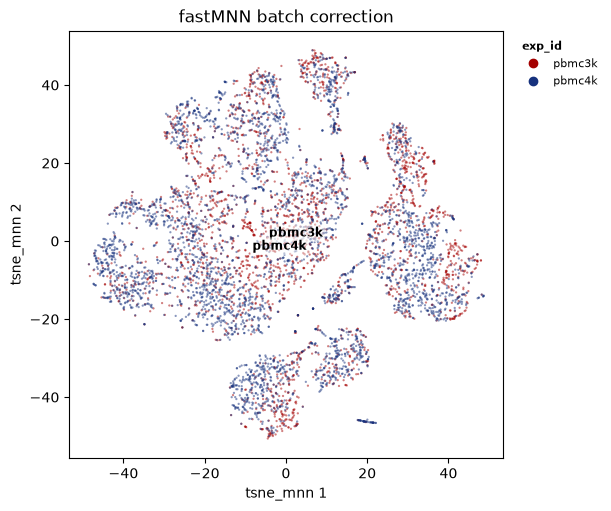

In [13]:
ax = bv.pl.embedding_plot(sc, "tsne_mnn", "exp_id", label_by="exp_id", discrete=True)
ax.set_title("fastMNN batch correction")
plt.show()

Also, visually the batches get mixed now.

### Harmony

Harmony operates on the PCA embedding directly. Leave `k` as `None` and the
number of clusters is set to one per 30 cells, capped at 100. Both versions
are supported and share one numerical core in Rust. They differ in the
diversity penalty, the ridge regression and how the ridge penalty gets set.
The intercept is never penalised in either. Let's start with the original:

#### Version 1

In [14]:
bv.integrate.harmony(sc, "exp_id")

bv.graph.find_neighbours(sc, embd_to_use="harmony")

Let's calculate the batch correction-related scores.

In [15]:
metrics_df = pl.concat(
    [
        metrics_df,
        bv.integrate.calculate_integration_metrics(
            sc, "exp_id", cell_type_column="cell_type", embd_to_use="harmony"
        ).with_columns(method=pl.lit("Harmony")),
    ]
)

metrics_df.filter(pl.col("method") == "Harmony")

embedding,kbet_accept,batch_asw,ilisi,pcr_comparison,clisi,cell_type_asw,graph_connectivity,method
str,f64,f64,f64,f64,f64,f64,f64,str
"""harmony""",0.882886,0.976697,0.642336,0.982121,1.0,0.667409,0.949966,"""Harmony"""


Also here, we observe improvements across the board.

In [16]:
bv.embed.tsne(
    sc,
    slot_name="tsne_harm",
    use_knn=True,
    params=bv.embed.tsne_defaults().set_params(approx="qd"),
)

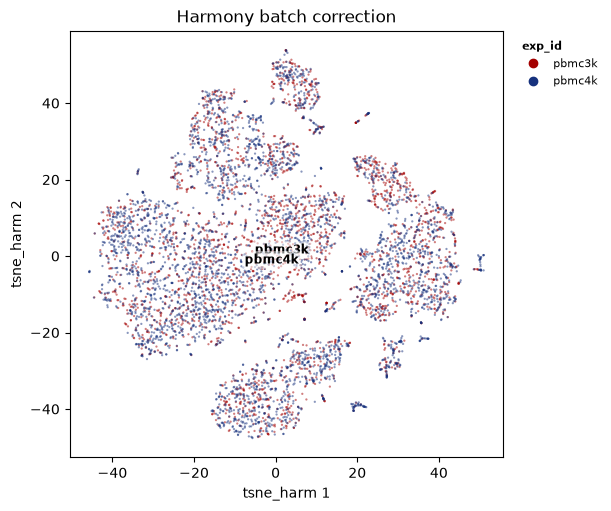

In [17]:
ax = bv.pl.embedding_plot(sc, "tsne_harm", "exp_id", label_by="exp_id", discrete=True)
ax.set_title("Harmony batch correction")
plt.show()

#### Version 2

[Patikas, et al., 2026](https://www.biorxiv.org/content/10.64898/2026.03.16.711825v1)
changed four things compared to v1. The last three have knobs in
`bv.params.HarmonyV2Params`:

- Stabilised diversity penalty, which makes the objective scale-invariant.
- Batch pruning in the ridge regression. A batch that puts less than
  `batch_proportion_cutoff` of its cells into a cluster is dropped from that
  cluster's regression. A cluster left with a single batch isn't corrected,
  so a cell type unique to one batch doesn't get pulled towards the others.
- Dynamic lambda. With `use_dynamic_lambda=True` (the default) the ridge
  penalty is set per cluster as `alpha` times the expected counts and the
  fixed `lambda_` is ignored.
- Theta scaling by batch size via `tau`. Off by default (`tau=0`).

The paper's arrowhead matrix inversion for a single batch covariate is used
by both versions here, so v1 gets that speed-up too. v2 also runs only 4
k-means iterations per Harmony round versus 20 in v1. Unless you need to
reproduce an old v1 result, go with v2.

In [18]:
bv.integrate.harmony_v2(sc, "exp_id")

bv.graph.find_neighbours(sc, embd_to_use="harmony_v2")

Let's calculate the batch correction-related scores.

In [19]:
metrics_df = pl.concat(
    [
        metrics_df,
        bv.integrate.calculate_integration_metrics(
            sc, "exp_id", cell_type_column="cell_type", embd_to_use="harmony_v2"
        ).with_columns(method=pl.lit("Harmony v2")),
    ]
)

metrics_df.filter(pl.col("method") == "Harmony v2")

embedding,kbet_accept,batch_asw,ilisi,pcr_comparison,clisi,cell_type_asw,graph_connectivity,method
str,f64,f64,f64,f64,f64,f64,f64,str
"""harmony_v2""",0.796408,0.97689,0.642336,0.948192,1.0,0.667918,0.949914,"""Harmony v2"""


In [20]:
bv.embed.tsne(
    sc,
    slot_name="tsne_harm_v2",
    use_knn=True,
    params=bv.embed.tsne_defaults().set_params(approx="qd"),
)

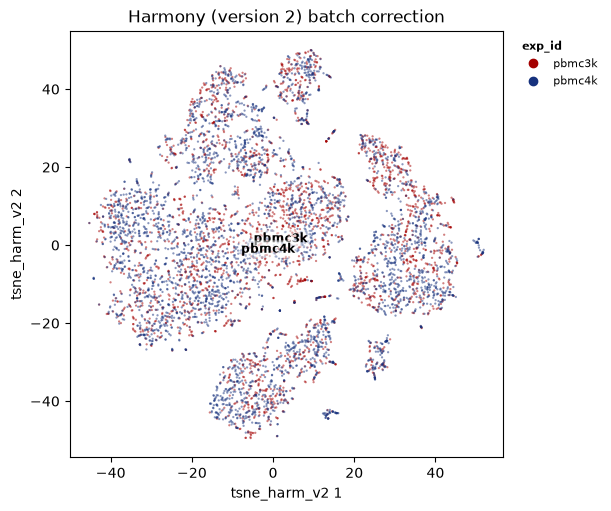

In [21]:
ax = bv.pl.embedding_plot(
    sc, "tsne_harm_v2", "exp_id", label_by="exp_id", discrete=True
)
ax.set_title("Harmony (version 2) batch correction")
plt.show()

Got a GPU? `bixverse_gpu.integrate.harmony_v2()` runs the same v2 algorithm
and stores the result as `"harmony_gpu"`. It takes a single batch column
only.

### Seurat CCA

Seurat's anchor methods take a different route. For each pair of batches they
find cells that are mutual nearest neighbours in a shared space, treat those
pairs as anchors, score them by how much of their neighbourhood they share,
and then apply a kernel-weighted correction that pulls the query batch onto
the reference. Batches get merged in the order of their pairwise anchor
counts.

For CCA the shared space is a canonical correlation embedding computed per
batch pair. Anchors also get filtered in gene space before scoring, which is
CCA-only in Seurat.

A few things differ from Seurat's reference implementation:

- The per-gene `ScaleData` step is skipped. We work directly from per-cell
  standardised log-normalised HVG expression.
- `M = X1^T @ X2` is never materialised. The canonical correlations come from
  a matrix-free randomised SVD, so memory stays at `O((n1 + n2) * num_cc)`
  rather than `n1 x n2`. On big batch pairs that is the difference between
  running and not running.
- The correction is applied to the embedding (dims x cells), not to full
  log-expression.
- The effective CC rank is `max(num_cc, dims)`, not `num_cc`.

Anchor structure comes out close to identical. Like fastMNN, CCA wants
batch-aware HVGs, so we reuse the ones computed above.

In [22]:
bv.integrate.seurat_cca(sc, "exp_id", batch_aware_hvg.hvg_gene_idx)

bv.graph.find_neighbours(sc, embd_to_use="cca")

In [23]:
metrics_df = pl.concat(
    [
        metrics_df,
        bv.integrate.calculate_integration_metrics(
            sc, "exp_id", cell_type_column="cell_type", embd_to_use="cca"
        ).with_columns(method=pl.lit("Seurat CCA")),
    ]
)

metrics_df.filter(pl.col("method") == "Seurat CCA")

embedding,kbet_accept,batch_asw,ilisi,pcr_comparison,clisi,cell_type_asw,graph_connectivity,method
str,f64,f64,f64,f64,f64,f64,f64,str
"""cca""",0.773317,0.956937,0.470588,0.978441,1.0,0.665292,0.949966,"""Seurat CCA"""


In [24]:
bv.embed.tsne(
    sc,
    slot_name="tsne_cca",
    use_knn=True,
    params=bv.embed.tsne_defaults().set_params(approx="qd"),
)

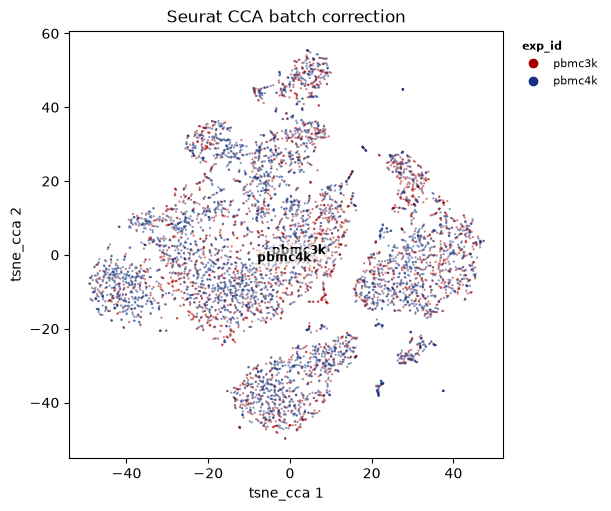

In [25]:
ax = bv.pl.embedding_plot(sc, "tsne_cca", "exp_id", label_by="exp_id", discrete=True)
ax.set_title("Seurat CCA batch correction")
plt.show()

### Seurat rPCA

rPCA runs the same anchor pipeline on a cheaper shared space. Instead of
computing canonical correlations, each batch keeps its own PCA basis and the
other batch's expression is projected into it. Cross-batch neighbour queries
then happen in these projected bases.

The trade-off is the usual one: rPCA is faster and corrects less
aggressively, which makes it the safer choice when your batches share most of
their cell types. CCA is the one to reach for when they don't. As in Seurat,
no gene-space anchor filter runs here, that step is CCA-only.

In [26]:
bv.integrate.seurat_rpca(sc, "exp_id", batch_aware_hvg.hvg_gene_idx)

bv.graph.find_neighbours(sc, embd_to_use="rpca")

In [27]:
metrics_df = pl.concat(
    [
        metrics_df,
        bv.integrate.calculate_integration_metrics(
            sc, "exp_id", cell_type_column="cell_type", embd_to_use="rpca"
        ).with_columns(method=pl.lit("Seurat rPCA")),
    ]
)

metrics_df.filter(pl.col("method") == "Seurat rPCA")

embedding,kbet_accept,batch_asw,ilisi,pcr_comparison,clisi,cell_type_asw,graph_connectivity,method
str,f64,f64,f64,f64,f64,f64,f64,str
"""rpca""",0.813764,0.967853,0.642336,0.942066,1.0,0.663173,0.949539,"""Seurat rPCA"""


In [28]:
bv.embed.tsne(
    sc,
    slot_name="tsne_rpca",
    use_knn=True,
    params=bv.embed.tsne_defaults().set_params(approx="qd"),
)

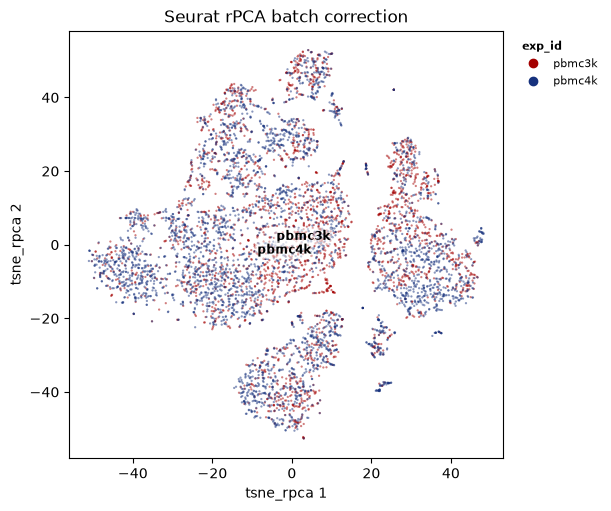

In [29]:
ax = bv.pl.embedding_plot(sc, "tsne_rpca", "exp_id", label_by="exp_id", discrete=True)
ax.set_title("Seurat rPCA batch correction")
plt.show()

One caveat worth knowing about both anchor methods: on data that already
mixes well they have nothing to gain, and the correction can nudge the batch
metrics slightly in the wrong direction while still sharpening the cell type
structure. Check your uncorrected metrics before reaching for them.

### BBKNN

BBKNN constructs a batch-balanced kNN graph rather than correcting an
embedding. The key parameter is `neighbours_within_batch`, which controls how
many neighbours are found per batch. Setting `no_neighbours_to_keep` below the
total generated neighbours (here 10 from 2 batches = 20 total) ensures the
distance-based filtering introduces genuine variation, making downstream
metrics informative.

Note that kBET and the embedding metrics are not well suited for evaluating
BBKNN: kBET compares neighbourhood proportions against global proportions,
which BBKNN manipulates by design, and ASW and PCR need an embedding. BBKNN
only hands back a graph, so we pass `embd_to_use=None` and those columns come
back null. iLISI, cLISI and graph connectivity on the stored kNN are the ones
to read here.

In [30]:
bv.integrate.bbknn(
    sc,
    "exp_id",
    no_neighbours_to_keep=15,
    bbknn_params=bv.params.BbknnParams(neighbours_within_batch=10),
)

/Users/gregorlueg/repos/shared/bixverse-rs/.claude/worktrees/proud-booping-matsumoto/python/bixverse/_core/integrate.py:530: UserWarning: Prior kNN matrix found. Will be overwritten.
  _bbknn(


In [31]:
metrics_df = pl.concat(
    [
        metrics_df,
        bv.integrate.calculate_integration_metrics(
            sc, "exp_id", cell_type_column="cell_type", embd_to_use=None
        ).with_columns(method=pl.lit("BBKNN")),
    ]
)

metrics_df.filter(pl.col("method") == "BBKNN")

embedding,kbet_accept,batch_asw,ilisi,pcr_comparison,clisi,cell_type_asw,graph_connectivity,method
str,f64,f64,f64,f64,f64,f64,f64,str
null,1.0,null,0.8,null,1.0,null,0.950153,"""BBKNN"""


In [32]:
bv.embed.tsne(sc, use_knn=True, params=bv.embed.tsne_defaults().set_params(approx="qd"))

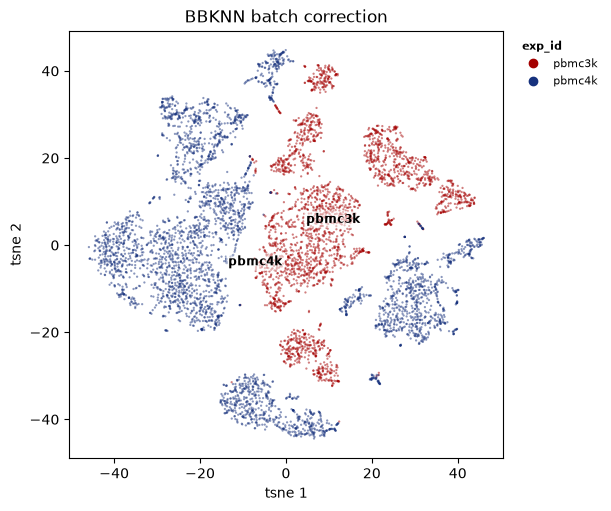

In [33]:
ax = bv.pl.embedding_plot(sc, "tsne", "exp_id", label_by="exp_id", discrete=True)
ax.set_title("BBKNN batch correction")
plt.show()

The t-SNE on the BBKNN graph barely mixes. The 5 cross-batch neighbours each
cell keeps sit further out than the 10 within its own batch, so the t-SNE
affinities give them little weight. iLISI on the graph tells the better story.

## Choosing a method

Here's everything side by side:

In [34]:
batch_metrics = ["kbet_accept", "batch_asw", "ilisi", "pcr_comparison"]
bio_metrics = ["clisi", "cell_type_asw", "graph_connectivity"]

metrics_df.select("method", *batch_metrics, *bio_metrics)

method,kbet_accept,batch_asw,ilisi,pcr_comparison,clisi,cell_type_asw,graph_connectivity
str,f64,f64,f64,f64,f64,f64,f64
"""Uncorrected""",0.012979,0.906355,0.0,null,1.0,0.650836,0.950153
"""fastMNN""",0.684576,0.973649,0.470588,0.960004,1.0,0.649202,0.948964
"""Harmony""",0.882886,0.976697,0.642336,0.982121,1.0,0.667409,0.949966
"""Harmony v2""",0.796408,0.97689,0.642336,0.948192,1.0,0.667918,0.949914
"""Seurat CCA""",0.773317,0.956937,0.470588,0.978441,1.0,0.665292,0.949966
"""Seurat rPCA""",0.813764,0.967853,0.642336,0.942066,1.0,0.663173,0.949539
"""BBKNN""",1.0,null,0.8,null,1.0,null,0.950153


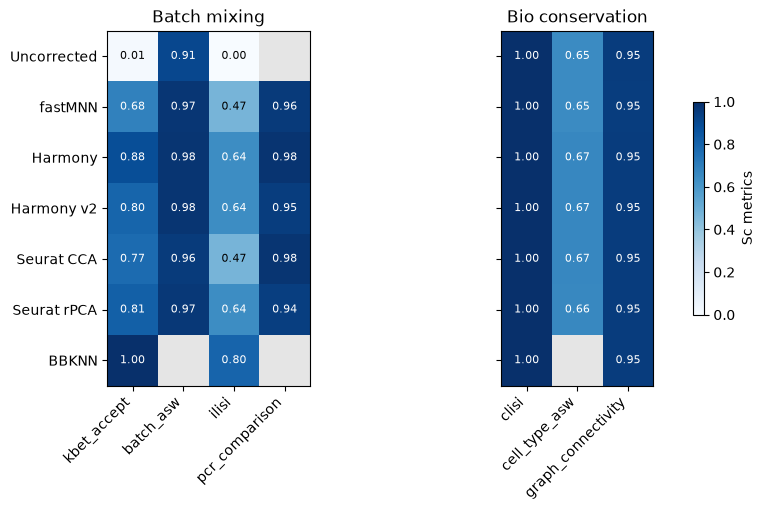

In [35]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(9, 5),
    sharey=True,
    layout="constrained",
    gridspec_kw={"width_ratios": [len(batch_metrics), len(bio_metrics)]},
)

methods = metrics_df["method"].to_list()
cmap = plt.get_cmap("Blues").with_extremes(bad="0.9")

for ax, cols, title in zip(
    axes,
    [batch_metrics, bio_metrics],
    ["Batch mixing", "Bio conservation"],
    strict=True,
):
    scores = metrics_df.select(cols).to_numpy().astype(np.float64)
    im = ax.imshow(np.ma.masked_invalid(scores), cmap=cmap, vmin=0, vmax=1)
    for i, j in np.ndindex(scores.shape):
        if not np.isnan(scores[i, j]):
            ax.text(
                j,
                i,
                f"{scores[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white" if scores[i, j] > 0.6 else "black",
            )
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
    ax.set_yticks(range(len(methods)), methods)
    ax.set_title(title)

fig.colorbar(im, ax=axes, label="Sc metrics", shrink=0.6)
plt.show()

Read the two panels together. A method that tops batch mixing but drops on
bio conservation has merged cell types along with the batches, which is worse
than doing nothing.

Two of these tell you little on this data set. cLISI sits at 1 for every
method: six coarse, well separated cell types keep their neighbourhoods pure
no matter what. Batch ASW barely moves either, since two PBMC batches of the
same tissue never separate much on silhouette to begin with. Both earn their
keep on finer labels and nastier batch effects. On two PBMC runs, kBET, iLISI
and PCR do the talking. And BBKNN's perfect kBET is the artefact mentioned
above, not a win.

There is no universally best batch correction method. Some practical
guidance:

- **Harmony** is a good default. It is fast, operates on the PCA embedding
  directly, and handles multiple batch variables simultaneously. It tends to
  work well when batch effects are moderate and cell type composition is
  broadly similar across batches. Version 2 is quite an improvement: it
  needs the same cells across the batches less, and is substantially faster
  when you provide only one batch effect to regress out.
- **fastMNN** is worth considering when cell type composition differs
  substantially across batches. The mutual nearest neighbour approach is less
  sensitive to this because it only aligns cells that have a plausible
  biological match in another batch.
- **Seurat CCA and rPCA** are the anchor-based options. Like fastMNN they
  only align cells with a plausible match in another batch, so they hold up
  when cell type composition differs. They are the heaviest of the five
  though, and on data that already mixes well they can make the batch metrics
  slightly worse. rPCA is the cheaper and gentler of the two and a sensible
  default; go to CCA when the batches genuinely don't share their cell types.
- **BBKNN** is useful when you want to avoid modifying the embedding at all.
  The batch-balanced graph can be passed directly to graph-based clustering
  algorithms. It is the lightest-touch approach but provides less control
  over the degree of correction.

In practice, running multiple methods and looking at quantitative metrics is
the most reliable approach. No single metric captures everything: kBET and
PCR only see batch, cLISI and cell type ASW only see biology, and the ones
built on the kNN graph are the only fair comparison for graph-based methods
like BBKNN. UMAPs and tSNE assessments should be taken with a big pinch of
salt, see
[Chari, et al.](https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1011288)
Admittedly, they do look pretty however.

## Clean up

In [36]:
tempdir_batch_cor.cleanup()